# Outros Distritos

In [10]:
import pandas as pd 
from sklearn.model_selection import train_test_split
from sklearn.neural_network import MLPRegressor
import pickle 
from tqdm import tqdm
import numpy as np
from sklearn.metrics import mean_squared_error

df_27 = pd.read_csv('df_outros.csv')
df_27_y = pd.read_csv('df_outros_y.csv')

df_27['ID'] = [i for i in range(len(df_27))]
df_27_y['ID'] = [i for i in range(len(df_27_y))]

# Coluna = 'Unnamed: 0' --> corresponde aos id reais!! <-- IMP

In [11]:
df_27 = df_27.drop(columns = ['timestamp', 'latitude', 'longitude'])
df_27

,built_in,tipology,amenities,m2,m2_util,energetic_efficiency,house_type,latitude_norm,longitude_norm,ID
0,True,0.142857,True,0.16,0.16,True,0.142857,0.692057,-0.070647,0
1,2012,0.285714,Swimming pool,0.12,0.12,a,0.285714,0.668239,-0.081023,1
2,2006,0.357143,True,0.16,0.10,f,0.428571,0.685003,-0.069626,2
3,2015,0.357143,Swimming pool,0.20,0.20,True,0.285714,0.672806,-0.238325,3
4,1978,0.142857,True,0.04,0.04,True,0.428571,0.692057,-0.070647,4
...,...,...,...,...,...,...,...,...,...,...
4484,True,0.214286,True,0.26,0.12,d,0.285714,0.691827,-0.069886,4484
4485,True,0.214286,Garden,0.10,0.08,True,0.142857,0.681463,-0.073539,4485
4486,True,0.285714,True,0.22,0.22,True,0.571429,0.667694,-0.079587,4486
4487,True,0.285714,Garden,0.26,0.26,f,0.571429,0.672570,-0.078310,4487


# Pre-processamento 

### Colunas: 
- built_in
- amenities
- energetic_efficiency

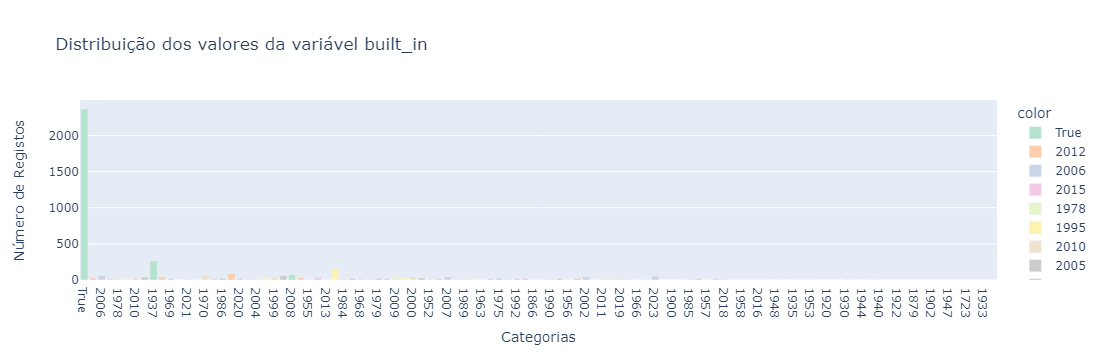

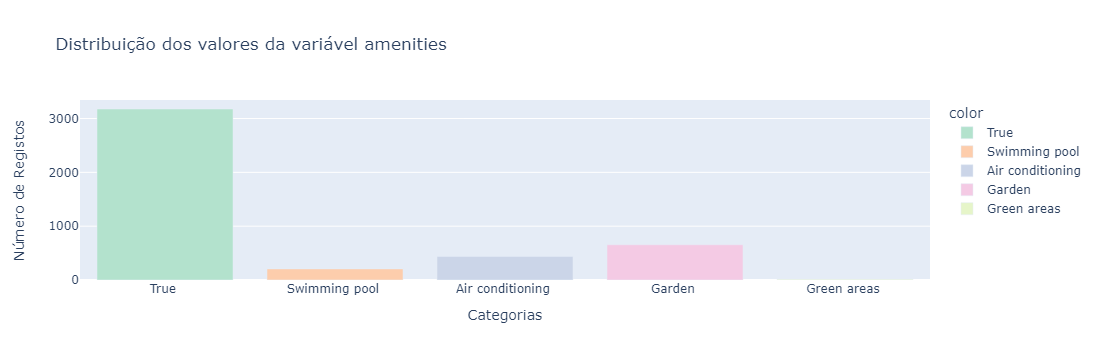

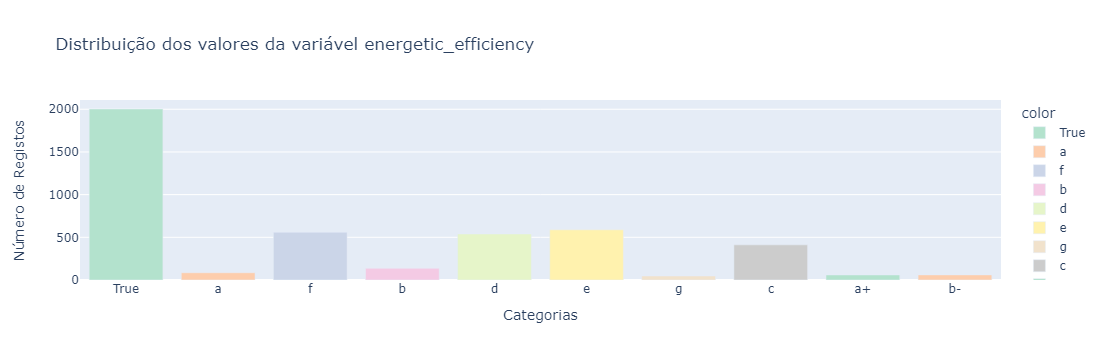

In [12]:
# Variação dos dados 
import plotly.express as px
col = ['built_in', 'amenities','energetic_efficiency']

for nome in col: 
    output = []
    names = df_27[nome].unique()
    for i in df_27[nome].unique():
        bt2 = df_27[nome].value_counts()[i]
        output.append(bt2)
    fig = px.bar(df_27, x=names, y=output, color = names ,color_discrete_sequence= px.colors.qualitative.Pastel2, title= f'Distribuição dos valores da variável {nome}')
    fig.update_xaxes(title_text='Categorias')
    fig.update_yaxes(title_text='Número de Registos')
    fig.show()

### --> Eficiência Energética

In [13]:
from sklearn.neighbors import KNeighborsClassifier
# Cluster para ver as casas mais parecidas, para depois asoociar um valor aos imóveis que não têm eficiencia energética

# Obter ID onde energetic_efficiency == 'True' e ou != 'True'
ids_true27 = list(df_27.loc[df_27['energetic_efficiency'] == 'True', 'ID']) # O que vão ser previstos 
ids_outros27 = list(df_27.loc[df_27['energetic_efficiency'] != 'True', 'ID'])


# Dados 
teste27 = df_27.loc[ids_true27,['tipology', 'm2', 'm2_util', 'house_type','latitude_norm', 'longitude_norm']]
#teste_y27 = df_27.loc[ids_true27,['energetic_efficiency']]
treino27 = df_27.loc[ids_outros27,['tipology', 'm2', 'm2_util', 'house_type','latitude_norm', 'longitude_norm']]
treino_y27 = df_27.loc[ids_outros27,['energetic_efficiency']]

# Comparação --> X_train_27[['tipology', 'm2', 'm2_util', 'house_type','latitude_norm', 'longitude_norm']]
def KNN(k, teste, treino, treino_y):
    knn =  KNeighborsClassifier(n_neighbors=k)
    knn.fit(treino, treino_y)
    y_pred = knn.predict(teste)
    return y_pred
l_ee27 = KNN(3, teste27, treino27, treino_y27)

# Substituir os True

def sub_ee(ids_true, l_ee, df, col):
    for i in range(len(ids_true)): 
        df.loc[df['ID'] == ids_true[i], col] = l_ee[i]
    return df
df_27 = sub_ee(ids_true27, l_ee27, df_27, 'energetic_efficiency')


ee27 = df_27.loc[:, ['energetic_efficiency']]

def substituir_energetic_efficiency(X):
    X = X.replace('a+', 1)
    X = X.replace('a', 2)
    X = X.replace('b', 3)
    X = X.replace('b-', 4)
    X = X.replace('c', 5)
    X = X.replace('d', 6)
    X = X.replace('e', 7)
    X = X.replace('f', 8)
    X = X.replace('g', 9)
    
    return X
ee27 = substituir_energetic_efficiency(ee27)

# normalizar valores 
def norm_ee(df1): 
    
    df1['energetic_efficiency'] = df1['energetic_efficiency'] /df1['energetic_efficiency'].abs().max()
    return df1
ee27 = norm_ee(ee27)

df_27['energetic_efficiency'] = ee27

C:\Users\User\AppData\Roaming\Python\Python311\site-packages\sklearn\neighbors\_classification.py:233: DataConversionWarning:

A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().



### --> Amenities

In [14]:
aa27 = df_27.loc[:, ['amenities']]

def substituir_amenities(X):
    X = X.replace('True ', 1)
    X = X.replace('Air conditioning ', 2)
    X = X.replace('Garden ', 3)
    X = X.replace('Green areas ', 3)
    X = X.replace('Swimming pool ', 4)
    
    return X
aa27 = substituir_amenities(aa27)

# normalizar valores 
def norm_amenities(df1): 
    
    df1['amenities'] = df1['amenities'] /11
    return df1
aa27 = norm_amenities(aa27)

df_27['amenities'] = aa27

### --> built_in

In [15]:
id_true27 = list(df_27.loc[df_27['built_in'] == 'True', 'ID'])
id_outros27 = list(df_27.loc[df_27['built_in'] != 'True', 'ID'])

# Obter anos que têm menos de 2 samples 

def menos_2(df, nome): 
    l = []
    for i in df[nome].unique():
        bt2 = df[nome].value_counts()[i]
        if bt2 < 3: 
            l.append(i) 
    return l
lista_data27 = menos_2(df_27, 'built_in')

def replicação_menos2(df, lista_data, id_outros):
    for ano in lista_data: 
        id_ano = list(df.loc[df['built_in'] == ano, 'ID'])
        for i in range(len(id_ano)):
            id_outros.append(id_ano[i])
            id_outros.append(id_ano[i])
    return id_outros

id_outros27 = replicação_menos2(df_27, lista_data27, id_outros27)

# Dados 
# criar dataset com price

d_b27 =  df_27.loc[:,['tipology', 'm2', 'm2_util', 'house_type','latitude_norm', 'longitude_norm']]
d_b_227 = df_27_y.loc[:,['Price_norm']]
#d_b = pd.concat([d_b_1, d_b_2])
d_b27 = d_b27.join(d_b_227)


teste_b27 = d_b27.loc[id_true27,['tipology', 'm2', 'm2_util', 'house_type','latitude_norm', 'longitude_norm','Price_norm']]
#teste_y27 = df_27.loc[ids_true27,['built_in']]
treino_b27 = d_b27.loc[id_outros27,['tipology', 'm2', 'm2_util', 'house_type','latitude_norm', 'longitude_norm','Price_norm']]
treino_b_y27 = df_27.loc[id_outros27,['built_in']]

# KNN
l_b_i27 = KNN(3, teste_b27, treino_b27, treino_b_y27)

# Substituir
df_27 = sub_ee(id_true27, l_b_i27, df_27, 'built_in')

b_i27 = df_27.loc[:, ['built_in']]
b_i27['built_in'] = b_i27['built_in'].astype(int)

# normalizar valores 
def norm_b_i(df1): 
    
    df1['built_in'] = df1['built_in'] /2024
    return df1
b_i27 = norm_b_i(b_i27)

df_27['built_in'] = b_i27

C:\Users\User\AppData\Roaming\Python\Python311\site-packages\sklearn\neighbors\_classification.py:233: DataConversionWarning:

A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().



In [16]:
df_27

,built_in,tipology,amenities,m2,m2_util,energetic_efficiency,house_type,latitude_norm,longitude_norm,ID
0,0.957510,0.142857,0.090909,0.16,0.16,0.222222,0.142857,0.692057,-0.070647,0
1,0.994071,0.285714,0.363636,0.12,0.12,0.222222,0.285714,0.668239,-0.081023,1
2,0.991107,0.357143,0.090909,0.16,0.10,0.888889,0.428571,0.685003,-0.069626,2
3,0.995553,0.357143,0.363636,0.20,0.20,0.555556,0.285714,0.672806,-0.238325,3
4,0.977273,0.142857,0.090909,0.04,0.04,0.888889,0.428571,0.692057,-0.070647,4
...,...,...,...,...,...,...,...,...,...,...
4484,0.987154,0.214286,0.090909,0.26,0.12,0.666667,0.285714,0.691827,-0.069886,4484
4485,0.963439,0.214286,0.272727,0.10,0.08,0.777778,0.142857,0.681463,-0.073539,4485
4486,0.987648,0.285714,0.090909,0.22,0.22,0.666667,0.571429,0.667694,-0.079587,4486
4487,0.978261,0.285714,0.272727,0.26,0.26,0.888889,0.571429,0.672570,-0.078310,4487


# Modelo

In [17]:

# Dividir em treino e teste

X_train_27, X_test_27, y_train_27, y_test_27 = train_test_split(df_27, df_27_y, test_size=0.30, random_state=42)
X_train_27

,built_in,tipology,amenities,m2,m2_util,energetic_efficiency,house_type,latitude_norm,longitude_norm,ID
1393,0.990613,0.285714,0.090909,0.26,0.18,0.666667,0.428571,0.689934,-0.251907,1393
25,0.954545,0.214286,0.090909,0.10,0.10,0.777778,0.428571,0.691240,-0.073690,25
658,0.957016,0.285714,0.090909,0.32,0.32,0.111111,0.571429,0.668299,-0.075102,658
2685,0.958004,0.357143,0.090909,0.40,0.36,0.111111,0.428571,0.673655,-0.238135,2685
2801,0.982708,0.357143,0.090909,0.32,0.24,0.333333,1.000000,0.672806,-0.238325,2801
...,...,...,...,...,...,...,...,...,...,...
4426,0.992095,0.214286,0.090909,0.16,0.08,0.888889,0.428571,0.441034,-1.000000,4426
466,0.993083,0.357143,0.272727,0.08,0.32,0.333333,0.142857,0.688531,-0.070191,466
3092,0.957016,0.071429,0.090909,0.06,0.06,0.666667,0.142857,0.672460,-0.234562,3092
3772,0.991107,0.214286,0.090909,0.12,0.12,0.333333,0.285714,0.672604,-0.238837,3772


In [18]:
X_train27 = X_train_27[['tipology', 'amenities', 'built_in','energetic_efficiency', 'house_type']]
X_test27 = X_test_27[[ 'tipology', 'amenities', 'built_in', 'energetic_efficiency', 'house_type']]
y_train27 = y_train_27[['Price_norm']]
y_test27 = y_test_27[['Price_norm']]

# GradientBoostingRegressor

In [28]:
"""
from sklearn import ensemble

gbd = ensemble.GradientBoostingRegressor(n_estimators = 100, max_depth = 8, min_samples_split = 2, learning_rate = 0.005, loss = 'squared_error')
gbd.fit(X_train27, y_train27)
y_pred_27 = gbd.predict(X_test27)
y_pred_27 = [abs(x) for x in y_pred_27]
#print(y_pred_27)
print(mean_squared_error(y_pred_27,y_test27))
print(gbd.score(X_test27,y_test27))

### Guardar o modelo

import pickle

with open('modelo_dist_outros.pkl', 'wb') as file:
    pickle.dump(gbd, file)

"""

C:\Users\User\AppData\Roaming\Python\Python311\site-packages\sklearn\ensemble\_gb.py:424: DataConversionWarning:

A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().



0.0017620044688127687
0.2695261323608894


In [31]:
# abrir modelo

with open('modelo_dist_outros.pkl', 'rb') as f:
    GBD = pickle.load(f)
GBD

GradientBoostingRegressor(learning_rate=0.005, max_depth=8)

In [33]:
y_prev = GBD.predict(X_test27)

# OUTPUT VIS

In [34]:
y_test27['prev_norm'] = y_prev

C:\Users\User\AppData\Local\Temp\ipykernel_11592\4018819711.py:1: SettingWithCopyWarning:


A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy



In [35]:
# Desnormalizar valores e Criar 'Price_prev'
def desnormalizar(valor):
    maximoout= 15000000 # depois mudar este valor, para o verdadeiro máximo
    return np.round(valor * maximoout,0)

def lista_des(lista): 
    n_l = []
    for i in lista: 
        n_l.append(desnormalizar(i))
    return n_l

y_test27['Price_prev'] = lista_des(y_prev)

def df_criar_id(y_test, df_13_y):
    y_test['Price_Real'] =[0] * len(y_test)
    for i in y_test.index:
        y_test['Price_Real'][i] = df_13_y['Price_Real'].iloc[i]
    return y_test
y_test27 = df_criar_id(y_test27, df_27_y)

C:\Users\User\AppData\Local\Temp\ipykernel_11592\2310009841.py:17: SettingWithCopyWarning:


A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy

C:\Users\User\AppData\Local\Temp\ipykernel_11592\2310009841.py:17: SettingWithCopyWarning:


A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy

C:\Users\User\AppData\Local\Temp\ipykernel_11592\2310009841.py:17: SettingWithCopyWarning:


A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy

C:\Users\User\AppData\Local\Temp\ipykernel_11592\2310009841.py:17: SettingWithCopyWarning:


A value

In [36]:
# Crirar intervalo de preço

def intervalo_preco(y):
    l =  []
    for i in y['Price_prev']: 
        p_int = [i-(i*0.03), i+(i*0.03)]
        l.append(p_int)
    y['Price_Prev_Int'] = l
    return y

y_test27 =  intervalo_preco(y_test27)

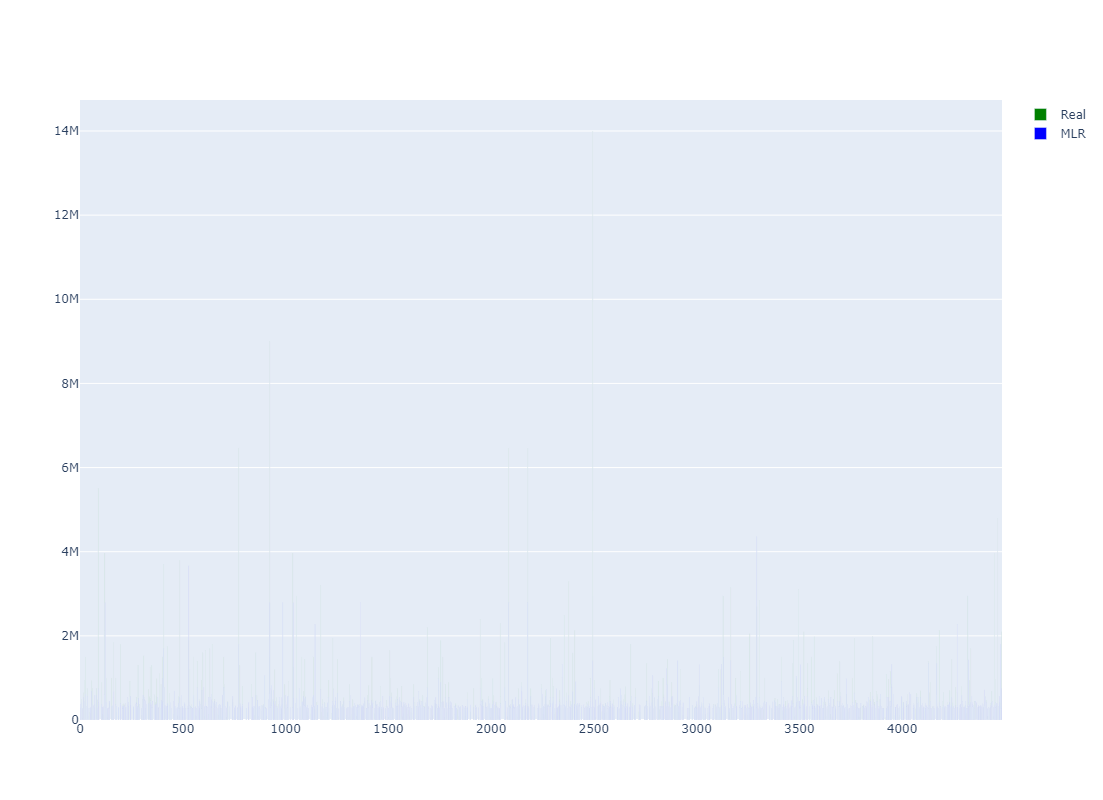

In [37]:
import plotly.graph_objects as go

# Grafico preço real e valor previsto
fig = go.Figure(
    data=[
        go.Bar(x=X_train_27.ID, y=y_test27.Price_Real, name="Real", marker_color='green'),
        go.Bar(x=X_train_27.ID, y=y_test27.Price_prev, name="MLR",  marker_color='blue'),
    ],
)
fig.update_layout(
    autosize=False,
    width=1000,
    height=800)

fig.show()